# Forest Proximity Tutorial (RF, ExtraTrees, RotationForest, IsolationForest)

This notebook demonstrates how to generate forest-based proximities using `forestgap`, embed them with PHATE, and compare embeddings across model families.

Workflow:
1. Set `TASK_TYPE` to `classification` or `regression` (single switch at top).
2. Load dataset and split train/test.
3. Build proximities for each forest model.
4. Compute PHATE embedding from each model's proximity matrix.
5. Compare all embeddings in one final subplot figure.

In [3]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    IsolationForest,
)

from forestgap import with_sparse_proximity

warnings.filterwarnings(
    "ignore",
    message=r".*BaseEstimator\._validate_data.*",
    category=FutureWarning,
)

try:
    from aeon.classification.sklearn import RotationForestClassifier
    from aeon.regression.sklearn import RotationForestRegressor
    HAS_AEON = True
except Exception:
    HAS_AEON = False

try:
    import phate
except Exception as exc:
    raise ImportError(
        "PHATE is required for this tutorial. Install with: pip install phate"
    ) from exc

## 1) Global Configuration
Use this single switch to toggle all supervised models between classification and regression.

In [4]:
# Toggle this value: 'classification' or 'regression'
TASK_TYPE = "classification"

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_ESTIMATORS = 100
N_JOBS = -1
PROX_METHOD = "rfgap"

# IsolationForest-specific toggle: proximities can be built with or without bootstrap sampling
ISO_BOOTSTRAP = True

DATA_DIR = Path("..") / "datasets"
DATASET_BY_TASK = {
    "classification": DATA_DIR / "iris.csv",
    "regression": DATA_DIR / "AirQuality",
}

if TASK_TYPE not in DATASET_BY_TASK:
    raise ValueError("TASK_TYPE must be either 'classification' or 'regression'.")

print(
    f"TASK_TYPE={TASK_TYPE}, PROX_METHOD={PROX_METHOD}, "
    f"N_ESTIMATORS={N_ESTIMATORS}, N_JOBS={N_JOBS}, ISO_BOOTSTRAP={ISO_BOOTSTRAP}"
)


TASK_TYPE=classification, PROX_METHOD=rfgap, N_ESTIMATORS=100, N_JOBS=-1, ISO_BOOTSTRAP=True


## 2) Dataset Loading
Classification reads `treeData.csv` (last column as target). Regression reads AirQuality from `x.txt` and `y.txt`.

In [5]:
def load_dataset(task_type: str):
    source = DATASET_BY_TASK[task_type]

    if task_type == "classification":
        path = source
        if not path.exists():
            raise FileNotFoundError(f"Dataset not found: {path.resolve()}")

        df = pd.read_csv(path)
        if df.shape[1] < 2:
            raise ValueError("Dataset must have at least one feature column and one target column.")

        # Prefer a non-numeric column as target (common in classification CSVs like iris).
        non_numeric_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
        if len(non_numeric_cols) >= 1:
            target_col = non_numeric_cols[-1]
        else:
            target_col = df.columns[-1]

        y_raw = df[target_col].copy()
        X = df.drop(columns=[target_col]).copy()
        le = LabelEncoder()
        y = le.fit_transform(y_raw.astype(str))
        target_names = list(le.classes_)
        dataset_label = path.name
        return X, np.asarray(y), target_names, dataset_label

    airquality_dir = source
    x_path = airquality_dir / "x.txt"
    y_path = airquality_dir / "y.txt"
    if not x_path.exists() or not y_path.exists():
        raise FileNotFoundError(
            f"AirQuality files not found. Expected: {x_path.resolve()} and {y_path.resolve()}"
        )

    X = pd.read_csv(x_path, header=None, sep=r"\s+")
    y = pd.read_csv(y_path, header=None).iloc[:, 0]
    y = pd.to_numeric(y, errors="coerce").to_numpy()
    if np.isnan(y).any():
        raise ValueError("Regression target contains non-numeric values.")

    dataset_label = f"{airquality_dir.name}/(x.txt,y.txt)"
    return X, np.asarray(y), None, dataset_label


X, y, target_names, dataset_name = load_dataset(TASK_TYPE)

stratify = y if TASK_TYPE == "classification" else None
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=stratify,
    )
except ValueError as exc:
    if TASK_TYPE == "classification" and "least populated class" in str(exc):
        print("Warning: falling back to non-stratified split due to sparse class counts.")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=None,
        )
    else:
        raise

print(f"Dataset: {dataset_name}")
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")


Dataset: iris.csv
Train shape: (112, 4), Test shape: (38, 4)


## 3) Shared Helpers
These utilities standardize fitting, proximity extraction, and PHATE embedding across models.

In [6]:
def to_dense(mat):
    return mat.toarray() if sparse.issparse(mat) else np.asarray(mat)


def phate_from_proximity(P, random_state=42):
    P_dense = to_dense(P)
    op = phate.PHATE(random_state=random_state, n_jobs=N_JOBS)
    emb = op.fit_transform(P_dense)
    return emb


def plot_embedding(ax, emb, labels, title, task_type):
    if task_type == "classification":
        ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="tab10")
    else:
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="viridis")
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

    ax.set_title(title)
    ax.set_xlabel("PHATE-1")
    ax.set_ylabel("PHATE-2")


class NotebookIsolationForestAdapter(IsolationForest):
    """Expose apply(X) at ensemble level for proximity construction."""
    def apply(self, X):
        X_arr = np.asarray(X)
        if not hasattr(self, "estimators_") or not hasattr(self, "estimators_features_"):
            raise RuntimeError("IsolationForest must be fitted before calling apply(X).")

        leaves = []
        for est, feats in zip(self.estimators_, self.estimators_features_):
            leaves.append(np.asarray(est.apply(X_arr[:, feats])))
        return np.column_stack(leaves)


def build_model_key_to_class(task_type):
    if task_type == "classification":
        mapping = {
            "RandomForest": RandomForestClassifier,
            "ExtraTrees": ExtraTreesClassifier,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestClassifier
    else:
        mapping = {
            "RandomForest": RandomForestRegressor,
            "ExtraTrees": ExtraTreesRegressor,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestRegressor

    mapping["IsolationForest"] = NotebookIsolationForestAdapter
    return mapping


def fit_and_get_proximity(model_name, model_cls, X_train, y_train, task_type):
    ProxCls = with_sparse_proximity(model_cls)

    if model_name == "IsolationForest":
        iso_kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "bootstrap": bool(ISO_BOOTSTRAP),
            "n_jobs": N_JOBS,
        }
        model = ProxCls(**iso_kwargs)

        if hasattr(model, "oob_score"):
            model.oob_score = False

        try:
            model.fit(X_train)
        except ValueError as exc:
            if "Out of bag estimation only available if bootstrap=True" in str(exc):
                if hasattr(model, "oob_score"):
                    model.oob_score = False
                model.fit(X_train)
            else:
                raise
    else:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        if "bootstrap" in model_cls.__init__.__code__.co_varnames:
            kwargs["bootstrap"] = True
        if "oob_score" in model_cls.__init__.__code__.co_varnames:
            kwargs["oob_score"] = (PROX_METHOD == "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train, y_train)

    P_train = model.get_proximities()
    return model, P_train

## 4) RandomForest Proximities + PHATE

Calculating PHATE...
  Running PHATE on 112 observations and 112 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.03 seconds.
    Calculating KNN search...
    Calculated KNN search in 2.21 seconds.
    Calculating affinities...
    Calculated affinities in 1.27 seconds.
  Calculated graph and diffusion operator in 3.51 seconds.
  Calculating optimal t...
    Automatically selected t = 12
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
  Calculated metric MDS in 0.07 seconds.
Calculated PHATE in 3.60 seconds.


c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\phate\phate.py:919: RuntimeWarning: Graph is disconnected with 2 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


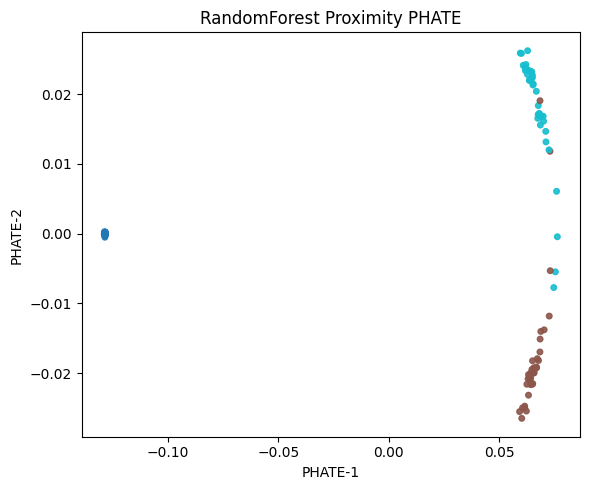

In [7]:
MODEL_MAP = build_model_key_to_class(TASK_TYPE)
results = {}

rf_model, rf_prox = fit_and_get_proximity("RandomForest", MODEL_MAP["RandomForest"], X_train, y_train, TASK_TYPE)
rf_emb = phate_from_proximity(rf_prox, random_state=RANDOM_STATE)
results["RandomForest"] = {"model": rf_model, "proximity": rf_prox, "embedding": rf_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, rf_emb, y_train, "RandomForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 5) ExtraTrees Proximities + PHATE

Calculating PHATE...
  Running PHATE on 112 observations and 112 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.03 seconds.
    Calculating KNN search...
    Calculating affinities...
  Calculated graph and diffusion operator in 0.04 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 2.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.10 seconds.
Calculated PHATE in 0.16 seconds.


c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\phate\phate.py:919: RuntimeWarning: Graph is disconnected with 2 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


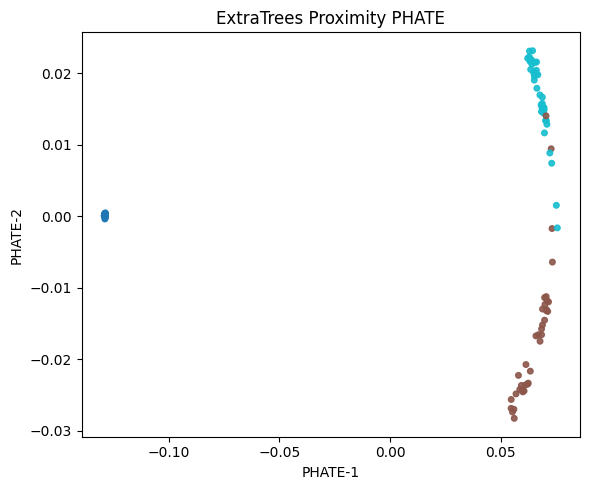

In [8]:
et_model, et_prox = fit_and_get_proximity("ExtraTrees", MODEL_MAP["ExtraTrees"], X_train, y_train, TASK_TYPE)
et_emb = phate_from_proximity(et_prox, random_state=RANDOM_STATE)
results["ExtraTrees"] = {"model": et_model, "proximity": et_prox, "embedding": et_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, et_emb, y_train, "ExtraTrees Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 6) RotationForest Proximities + PHATE
This section runs only when `aeon` is installed.

Calculating PHATE...
  Running PHATE on 112 observations and 112 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.02 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
  Calculated graph and diffusion operator in 0.04 seconds.
  Calculating optimal t...
    Automatically selected t = 11
  Calculated optimal t in 0.02 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 6.8% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.06 seconds.
Calculated PHATE in 0.12 seconds.


c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\phate\phate.py:919: RuntimeWarning: Graph is disconnected with 2 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


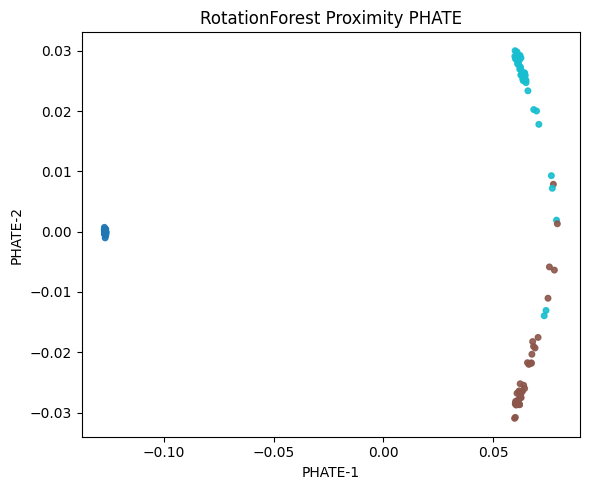

In [9]:
if "RotationForest" in MODEL_MAP:
    rot_model, rot_prox = fit_and_get_proximity("RotationForest", MODEL_MAP["RotationForest"], X_train, y_train, TASK_TYPE)
    rot_emb = phate_from_proximity(rot_prox, random_state=RANDOM_STATE)
    results["RotationForest"] = {"model": rot_model, "proximity": rot_prox, "embedding": rot_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, rot_emb, y_train, "RotationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping RotationForest section because aeon is not installed.")


## 7) IsolationForest Proximities + PHATE
IsolationForest is unsupervised; we still color points by target values for visual comparison.

Calculating PHATE...
  Running PHATE on 112 observations and 112 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.03 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
  Calculated graph and diffusion operator in 0.05 seconds.
  Calculating optimal t...
    Automatically selected t = 12
  Calculated optimal t in 0.02 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
  Calculated metric MDS in 0.09 seconds.
Calculated PHATE in 0.17 seconds.


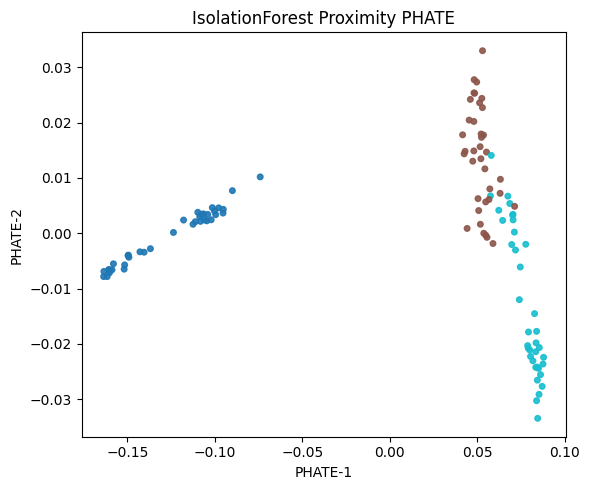

In [10]:
iso_model, iso_prox = fit_and_get_proximity("IsolationForest", MODEL_MAP["IsolationForest"], X_train, y_train, TASK_TYPE)
iso_emb = phate_from_proximity(iso_prox, random_state=RANDOM_STATE)
results["IsolationForest"] = {"model": iso_model, "proximity": iso_prox, "embedding": iso_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, iso_emb, y_train, "IsolationForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 8) Final Comparison: All Forest Proximity PHATE Embeddings
This summary figure compares all available model embeddings in one place.

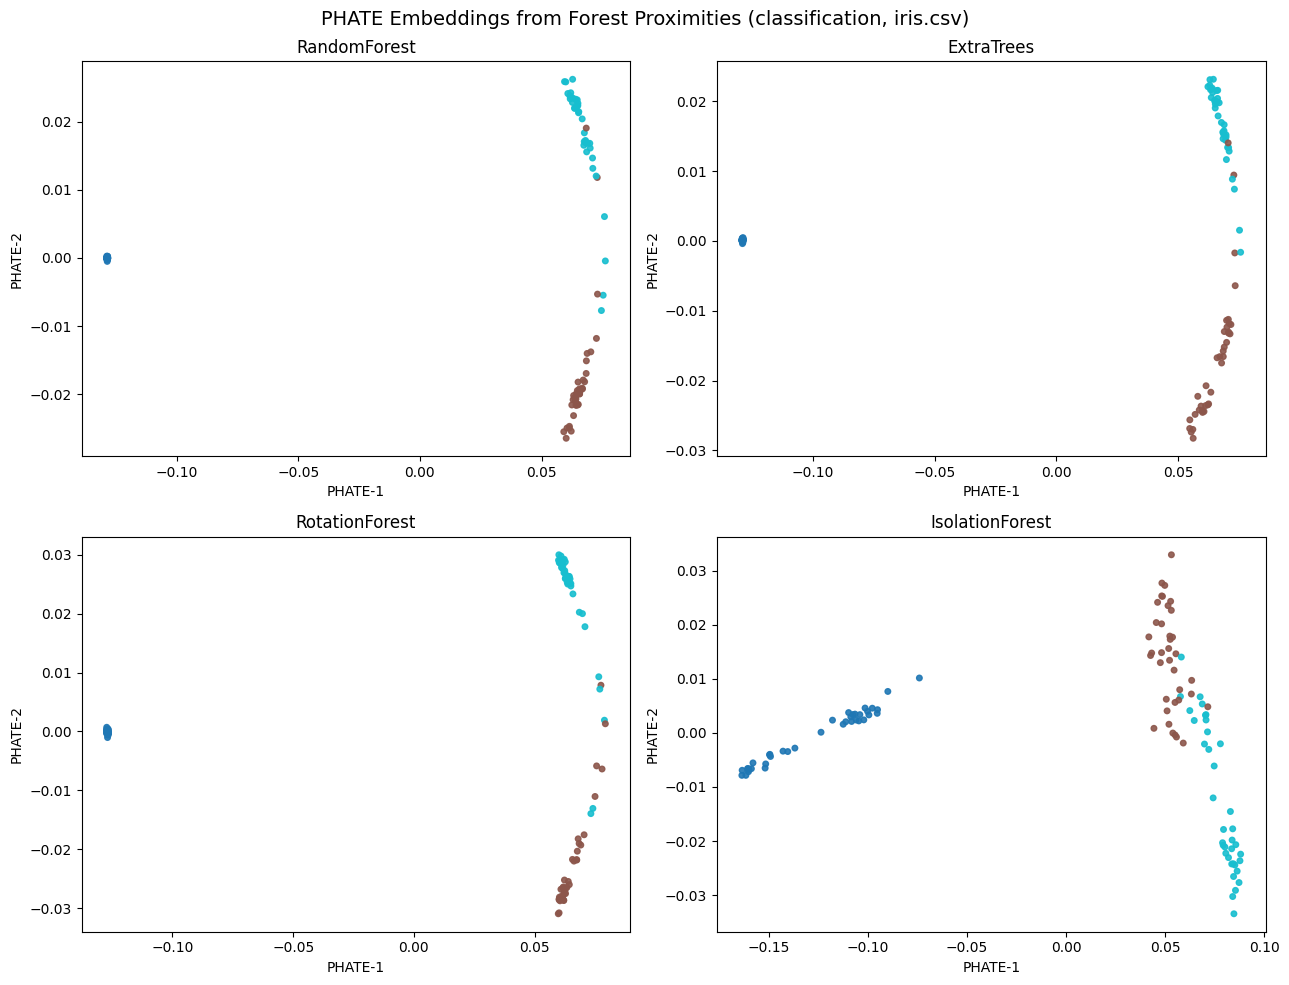

In [11]:
model_order = ["RandomForest", "ExtraTrees", "RotationForest", "IsolationForest"]
available = [m for m in model_order if m in results]

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=False, sharey=False)
axes = axes.ravel()

for i, model_name in enumerate(model_order):
    ax = axes[i]
    if model_name not in available:
        ax.axis("off")
        ax.set_title(f"{model_name} (not available)")
        continue

    emb = results[model_name]["embedding"]
    plot_embedding(ax, emb, y_train, f"{model_name}", TASK_TYPE)

fig.suptitle(f"PHATE Embeddings from Forest Proximities ({TASK_TYPE}, {dataset_name})", fontsize=14)
plt.tight_layout()
plt.show()
